In [1]:
%matplotlib inline
import os
import cv2
from skimage.morphology import remove_small_objects
from skimage.morphology import skeletonize
import matplotlib.pyplot as plt
import numpy as np
from tifffile import tifffile
import ipywidgets as widgets
from ipywidgets import interact

In [2]:
def process_and_display(gain, threshold, kernel_size):
    infile = "014.tif"
    image_path = f"/net/birdstore/Active_Atlas_Data/data_root/pipeline_data/DK283/preps/C2/polygons"
    image_inpath = os.path.join(image_path, infile)
    with tifffile.TiffFile(image_inpath) as tif:
        img = tif.asarray()

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    #left side image, original * gain so you can see it
    modified_img = img.astype(np.uint32) * gain
    gained_img = np.clip(modified_img, 0, 65535).astype(np.uint16)

    _max = img.max()
    axes[0].imshow(gained_img, cmap="gray")
    axes[0].set_title(f"Original with gain: {gain} max before gain: {_max}")
    axes[0].axis("off")

    #right side image with threshold and gain
    #clipped = np.clip(img, threshold, 65535)
    #modified_values = clipped.astype(np.uint32) * gain
    #int8_arr = np.clip(modified_values, 0, 65535).astype(np.uint16)
    #pixel_count = np.count_nonzero(clipped)
    
    binary_mask = img > threshold
    # Apply morphological opening
    if kernel_size > 0:
        binary_mask = remove_small_objects(binary_mask, max_size=kernel_size)
    pixel_count = np.count_nonzero(binary_mask)
    int8_arr = (binary_mask * 255).astype(np.uint8)
    
    axes[1].imshow(int8_arr, cmap="gray")
    axes[1].set_title(f"Binary image with threshold: {threshold} with pixel count: {pixel_count}")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

In [3]:
interact(process_and_display,
    gain=widgets.IntSlider(min=0, max=25, step=1, value=10, description="Gain"),
    threshold=widgets.IntSlider(min=0, max=65000, step=10, value=0, description="Threshold"),
    kernel_size=widgets.IntSlider(min=0, max=500, step=5, value=0, description="Min area"),
)


interactive(children=(IntSlider(value=10, description='Gain', max=25), IntSlider(value=0, description='Thresho…

<function __main__.process_and_display(gain, threshold, kernel_size)>

In [4]:
infile = "014.tif"
image_path = f"/net/birdstore/Active_Atlas_Data/data_root/pipeline_data/DK283/preps/C2/polygons"
image_inpath = os.path.join(image_path, infile)
with tifffile.TiffFile(image_inpath) as tif:
    img = tif.asarray()

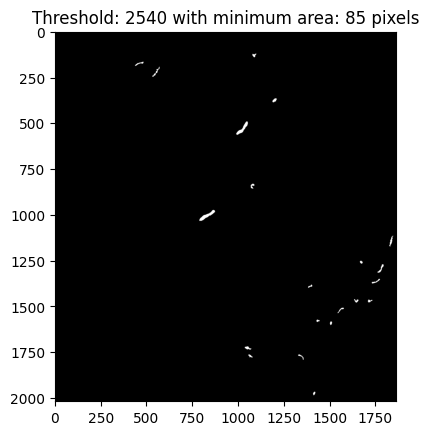

In [5]:
threshold = 2540
minimum_area = 85
binary_mask = img > threshold
int8_arr = (binary_mask * 255).astype(np.uint8)
contours, _ = cv2.findContours(int8_arr, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
empty = np.zeros_like(int8_arr)
for i, contour in enumerate(contours):
    #perimeter = cv2.arcLength(contour, closed=True)
    area = cv2.contourArea(contour)
    if area > minimum_area:
        cv2.drawContours(empty, contour, -1, 255, 2)
        cv2.fillPoly(empty, [contour], 255)
plt.title(f"Threshold: {threshold} with minimum area: {minimum_area} pixels")
plt.imshow(empty, cmap='gray')

[  0 255]
[3672158   93277]


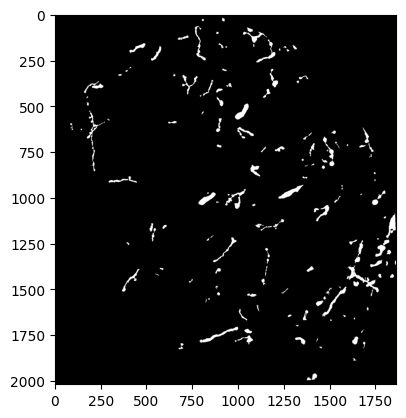

In [17]:
binary_mask = img > 750
# Apply morphological opening
binary_mask = remove_small_objects(binary_mask, max_size=50)
int8_arr = (binary_mask * 255).astype(np.uint8)
#int8_arr = cv2.bitwise_not(int8_arr)
plt.imshow(int8_arr, cmap='gray')
ids, counts = np.unique(int8_arr, return_counts = True)
print(ids)
print(counts)

In [18]:
outpath = "/net/birdstore/Active_Atlas_Data/data_root/pipeline_data/DK283/preps/C2/testing/int8_arr.png"
bgr_img = cv2.cvtColor(int8_arr, cv2.COLOR_GRAY2BGR)
ids, counts = np.unique(bgr_img, return_counts = True)
print(ids)
print(counts)
# 3. Save the 3-channel image to disk
cv2.imwrite(outpath, bgr_img)

[  0 255]
[11016474   279831]


True

In [43]:
inpath = "/net/birdstore/Active_Atlas_Data/data_root/pipeline_data/DK283/preps/C2/testing/int8_arr.png"
colored = cv2.imread(inpath)
colored[:, :, (1, 2)] = 255
print(red)
print(colored.shape)
ids, counts = np.unique(colored, return_counts = True)
print(ids)
print(counts)

0
(2019, 1865, 3)
[  0 255]
[3679163 7617142]


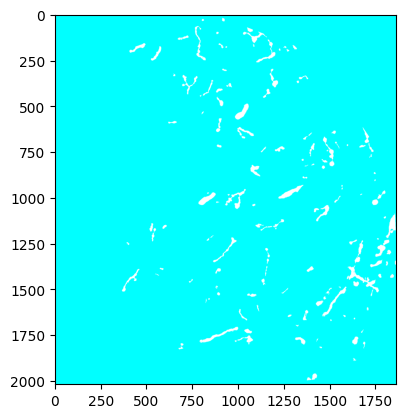

In [44]:
plt.imshow(colored, cmap='gray')